# Morphing two syllables (WORLD + DTW)

**Division of labor**
- **DTW** answers *when*: which frame of A corresponds to which frame of B.
- **WORLD** splits each sound into f0, spectral envelope and aperiodicity, which are interpolated separately after alignment.

Install once: `pip install pyworld librosa soundfile matplotlib`

### The algorithm works best when sounds are similar in duration and fundamental frequency, e.g. two Zebra finch calls, the same word spoken by two different people. For example, trying to morph a Canary song with a Zebra finch song will yield incorrect, cross-faded sounds rather than a continuous mixture of morphs due vast spectrotemporal differences!
### Always inspect sounds (visually and via spectrograms) and the peak_freq curves. The latter mut be near the identity line, which will align with the sound-spectrograms showing a more continuous morph. In turn, sounds should not sound cross-faded (i.e. two sounds on top of each other), the transition must be smooth to assume the morph worked.


# Example use-cases below
### The algorithm was used to morph Zebra finch calls and songs. It will work better on sound elements like calls, given their relative simplicity. Songs can be morphed, but one may have to find song-pairs that optimally work well together.

### These stimuli were used to assess if NCM neurons generate acoustic categories, and whether this is reflected by a neural psychometric curve. Behavioral or electrophysiological experiments are great use-cases. 

## 1. Settings (edit these)

In [ ]:
# change paths for your own stimuli

### good combo
PATH_A = r"Z:\SYL1.wav"  
PATH_B = r"Z:\SYL2.wav"
###

### good combo
PATH_A = r"Z:\song10.wav"
PATH_B = r"Z:\song11.wav"
###


N_STEPS = 7     # number of expected mixtures between sound A and B.

FS = 44100                       # both files resampled to this
FRAME_MS = 2.0                   #integration windows, short frames for brief syllables; try 5 for longer sounds
# f0 search range PER SOUND (Hz). Put the floor just below the lowest TRUE fundamental you can see in the spectrogram.
# Too low a floor -> tracker locks onto subharmonics (octave errors) AND uses a long analysis window
# that smears fast sweeps, which WORLD then reports as "aperiodic" and resynthesizes as noise.
F0_RANGE_A = (700.0, 6000.0)
F0_RANGE_B = (700.0, 6000.0)
NFFT = 1024
SMOOTH_F0 = 5      # median-filter length (frames, odd) to remove f0 jumps; 0 = off
FMAX_PLOT = 8000   # max frequency for plotting purposes

## 2. Imports and functions

In [ ]:
import numpy as np
import librosa
import librosa.display
import pyworld as pw
import soundfile as sf
import matplotlib.pyplot as plt

from IPython.display import Audio, display


def analyze(path, f0_range):
    """
    Extract pitch and spectral features from an audio file using WORLD.

    The audio is converted to a mono signal at the project's fixed sampling
    rate. WORLD is then used to estimate the fundamental frequency (F0),
    spectral envelope, and aperiodicity for subsequent voice morphing.

    Parameters
    ----------
    path : str or pathlib.Path
        Path to the input audio file.
    f0_range : tuple of (float, float)
        Minimum and maximum expected fundamental frequencies, in Hz.

    Returns
    -------
    dict
        Dictionary containing:
        - x: Audio waveform as a float64 NumPy array.
        - f0: Estimated fundamental frequency for each analysis frame.
        - t: Time associated with each F0 analysis frame.
        - sp: Spectral envelope estimated by WORLD.
        - ap: Aperiodicity estimates used during synthesis.
        - nfft: FFT size used for spectral analysis.
    """
    # Unpack the expected pitch range for the source recording.
    f0_floor, f0_ceil = f0_range

    # Load a mono waveform at the shared sampling rate used throughout
    # the analysis and synthesis pipeline.
    x, _ = librosa.load(path, sr=FS, mono=True)
    x = x.astype(np.float64)

    # Estimate F0 and its corresponding frame times using WORLD's Harvest
    # algorithm, which is designed for robust pitch extraction.
    f0, t = pw.harvest(
        x,
        FS,
        f0_floor=f0_floor,
        f0_ceil=f0_ceil,
        frame_period=FRAME_MS
    )

    # Optionally smooth the pitch contour to reduce isolated estimation
    # fluctuations while preserving frames identified as unvoiced.
    if SMOOTH_F0 and SMOOTH_F0 > 1:
        from scipy.signal import medfilt

        voiced = f0 > 0
        f0 = np.where(voiced, medfilt(f0, SMOOTH_F0), 0.0)

    # Use a fixed FFT size so that both recordings have compatible
    # spectral-bin layouts. This also avoids very small FFT sizes that
    # can cause problems with WORLD's aperiodicity estimation.
    nfft = NFFT

    # Estimate the spectral envelope, which describes how energy is
    # distributed across frequencies at each analysis frame.
    sp = pw.cheaptrick(
        x,
        f0,
        t,
        FS,
        f0_floor=f0_floor,
        fft_size=nfft
    )

    # Estimate spectral aperiodicity, describing the noise-like component
    # of the signal relative to its periodic component.
    ap = pw.d4c(x, f0, t, FS, fft_size=nfft)

    # Keep the extracted features together for downstream alignment
    # and interpolation during morphing.
    return {
        "x": x,
        "f0": f0,
        "t": t,
        "sp": sp,
        "ap": ap,
        "nfft": nfft
    }


def align(a, b):
    """
    Align two audio feature sequences using dynamic time warping (DTW).

    Mel-frequency cepstral coefficients (MFCCs) are calculated from the
    log spectral envelopes and used to identify corresponding frames
    between recordings. Alignment is based on spectral characteristics
    rather than directly on pitch.

    Parameters
    ----------
    a, b : dict
        Feature dictionaries returned by `analyze`.

    Returns
    -------
    tuple of numpy.ndarray
        Two floating-point index arrays, (ia, ib), identifying
        corresponding frames in recordings A and B.
    """
    # Calculate MFCCs from the log spectral envelopes. The small constant
    # prevents taking the logarithm of zero.
    fa = librosa.feature.mfcc(
        S=np.log(a["sp"] + 1e-12).T,
        n_mfcc=20
    )
    fb = librosa.feature.mfcc(
        S=np.log(b["sp"] + 1e-12).T,
        n_mfcc=20
    )

    # Find the lowest-cost alignment between the two feature sequences.
    # The Euclidean distance measures dissimilarity between MFCC frames.
    _, wp = librosa.sequence.dtw(
        X=fa,
        Y=fb,
        metric="euclidean"
    )

    # Librosa returns the warping path in reverse temporal order.
    # Reverse it so that the indices progress from the beginning to the end.
    wp = wp[::-1]

    # Return separate index arrays for the two recordings.
    # Floating-point indices allow later interpolation between frames.
    return wp[:, 0].astype(float), wp[:, 1].astype(float)


def frame_interp(M, idx):
    """
    Interpolate a frame-by-feature matrix at fractional frame indices.

    Linear interpolation allows the spectral envelope or aperiodicity
    matrix to be sampled at non-integer positions along the DTW path.

    Parameters
    ----------
    M : numpy.ndarray, shape (n_frames, n_features)
        Feature matrix to interpolate.
    idx : array-like
        Frame indices, which may contain fractional values.

    Returns
    -------
    numpy.ndarray
        Interpolated feature matrix with one row per requested index.
    """
    # Restrict indices to valid frame positions to prevent out-of-bounds
    # indexing at the beginning or end of the recording.
    idx = np.clip(idx, 0, M.shape[0] - 1)

    # Identify the neighboring frames surrounding each fractional index.
    lo = np.floor(idx).astype(int)
    hi = np.minimum(lo + 1, M.shape[0] - 1)

    # Calculate the relative contribution of the upper frame.
    # Add a singleton dimension so the weights broadcast across features.
    w = (idx - lo)[:, None]

    # Blend neighboring frames according to their relative distances.
    return (1 - w) * M[lo] + w * M[hi]


def f0_at(f0, idx):
    """
    Interpolate fundamental frequency at fractional frame indices.

    Positive F0 values represent voiced frames; zero indicates an
    unvoiced frame. Positive frequencies are interpolated in log space,
    which treats proportional pitch changes more naturally than linear
    interpolation in Hz.

    When the two neighboring frames disagree about voicing, use the
    closer frame's value rather than interpolating between zero and
    a positive frequency.

    Parameters
    ----------
    f0 : numpy.ndarray
        Fundamental-frequency contour.
    idx : array-like
        Fractional frame indices at which to estimate F0.

    Returns
    -------
    numpy.ndarray
        Interpolated F0 values, with zero retained for unvoiced frames.
    """
    # Keep indices within the available pitch contour.
    idx = np.clip(idx, 0, len(f0) - 1)

    # Locate the neighboring frames and compute interpolation weights.
    lo = np.floor(idx).astype(int)
    hi = np.minimum(lo + 1, len(f0) - 1)
    w = idx - lo

    # Log-frequency interpolation is only valid when both neighboring
    # frames are voiced.
    both = (f0[lo] > 0) & (f0[hi] > 0)

    # Interpolate voiced frames in log space. The maximum operation
    # prevents taking a logarithm of zero.
    log_interp = np.exp(
        (1 - w) * np.log(np.maximum(f0[lo], 1))
        + w * np.log(np.maximum(f0[hi], 1))
    )

    # If only one neighboring frame is voiced, select the closer frame
    # rather than creating an artificial intermediate pitch.
    nearest = np.where(w < 0.5, f0[lo], f0[hi])

    return np.where(both, log_interp, nearest)


def morph(a, b, ia, ib, p):
    """
    Generate an intermediate audio signal between two recordings.

    The recordings are aligned using DTW before their features are
    interpolated. The parameter `p` controls the relative contribution
    of each recording: 0 reproduces A's features and timing, while 1
    reproduces B's features and timing.

    Spectral envelopes are blended in log space, aperiodicity is blended
    linearly, and F0 is interpolated in log space when both recordings
    are voiced. The resulting features are passed to WORLD for synthesis.

    Parameters
    ----------
    a, b : dict
        Feature dictionaries returned by `analyze`.
    ia, ib : array-like
        Corresponding frame indices from `align`.
    p : float
        Morphing coefficient, where 0 corresponds to A and 1 to B.

    Returns
    -------
    numpy.ndarray
        Synthesized audio waveform for the requested morphing coefficient.
    """
    # Record the original feature-sequence lengths.
    nA = a["sp"].shape[0]
    nB = b["sp"].shape[0]

    # Interpolate the output duration as well as the acoustic features.
    # Rounding converts the weighted frame count to an integer.
    T = int(round((1 - p) * nA + p * nB))

    # Map each DTW correspondence to its weighted temporal position.
    # At p=0 the path follows A's frame indices; at p=1 it follows B's.
    # A small increasing offset prevents duplicate positions that would
    # otherwise make the interpolation axis non-increasing.
    t_out = (1 - p) * ia + p * ib + 1e-6 * np.arange(len(ia))

    # Construct a regularly indexed output timeline and map it back
    # onto the aligned frame coordinates of each original recording.
    k = np.arange(T)
    pa = np.interp(k, t_out, ia)
    pb = np.interp(k, t_out, ib)

    # Blend spectral envelopes in log space. This makes interpolation
    # multiplicative in the original spectral domain and helps avoid
    # overly attenuated intermediate spectral values.
    sp = np.exp(
        (1 - p) * frame_interp(np.log(a["sp"] + 1e-12), pa)
        + p * frame_interp(np.log(b["sp"] + 1e-12), pb)
    )

    # Blend aperiodicity estimates linearly at corresponding aligned
    # positions in the two recordings.
    ap = (
        (1 - p) * frame_interp(a["ap"], pa)
        + p * frame_interp(b["ap"], pb)
    )

    # Interpolate each recording's F0 contour along its mapped timeline.
    fA = f0_at(a["f0"], pa)
    fB = f0_at(b["f0"], pb)

    # When both recordings are voiced, interpolate pitch in log space.
    # When only one is voiced, retain that recording's pitch estimate.
    f0 = np.where(
        (fA > 0) & (fB > 0),
        np.exp(
            (1 - p) * np.log(np.maximum(fA, 1))
            + p * np.log(np.maximum(fB, 1))
        ),
        np.where(fA > 0, fA, fB)
    )

    # Explicitly preserve unvoiced frames when neither recording
    # contributes a positive F0 estimate.
    f0 = np.where((fA > 0) | (fB > 0), f0, 0.0)

    # Resynthesize the waveform from the interpolated WORLD parameters.
    return pw.synthesize(f0, sp, ap, FS, FRAME_MS)

## 3. Analyze and sanity-check the inputs

Check the f0 tracks before anything else. If they are broken, every morph will be too.

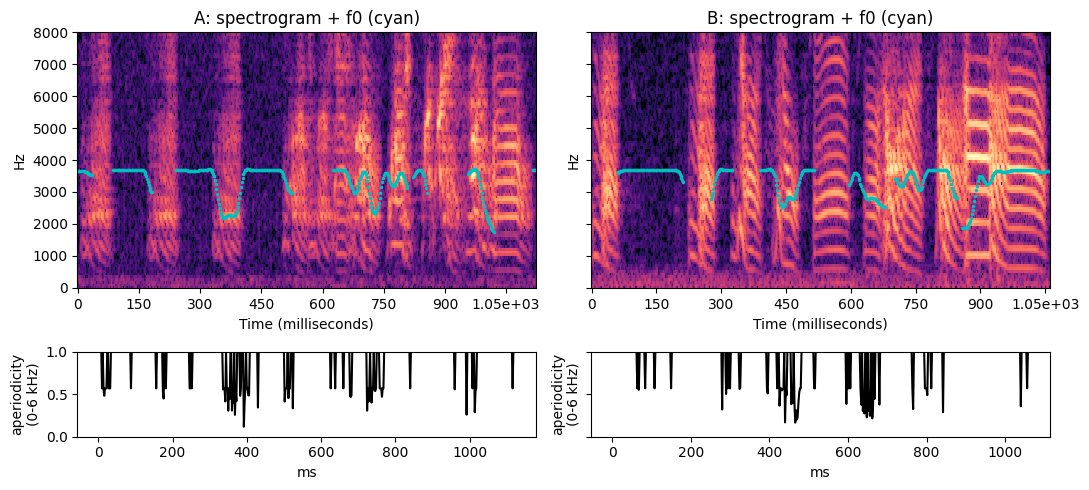

A: 1123 ms   B: 1060 ms
A: voiced frames = 64%, median f0 = 3635 Hz
B: voiced frames = 73%, median f0 = 3639 Hz
If voiced is low (<~70%) or median f0 is outside your F0_RANGE, fix the range or use Method 2 below.


In [17]:
a, b = analyze(PATH_A, F0_RANGE_A), analyze(PATH_B, F0_RANGE_B)

fig, ax = plt.subplots(2, 2, figsize=(11, 5), sharey="row", gridspec_kw=dict(height_ratios=[3, 1]))
for j, (s, name) in enumerate(zip((a, b), ("A", "B"))):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(s["x"], n_fft=512, hop_length=64)), ref=np.max)
    librosa.display.specshow(S, sr=FS, hop_length=64, x_axis="ms", y_axis="hz", ax=ax[0, j], cmap="magma")
    f0 = np.where(s["f0"] > 0, s["f0"], np.nan)
    ax[0, j].plot(s["t"], f0, "c.", ms=3)
    ax[0, j].set_title(f"{name}: spectrogram + f0 (cyan)"); ax[0, j].set_ylim(0, FMAX_PLOT)
    kmax = int(6000 / (FS / s["nfft"]))
    ax[1, j].plot(s["t"] * 1000, s["ap"][:, :kmax].mean(1), "k")
    ax[1, j].set_ylim(0, 1); ax[1, j].set_xlabel("ms"); ax[1, j].set_ylabel("aperiodicity\n(0-6 kHz)")
plt.tight_layout(); plt.show()
print(f"A: {len(a['x'])/FS*1000:.0f} ms   B: {len(b['x'])/FS*1000:.0f} ms")
for name, sd in (("A", a), ("B", b)):
    v = sd["f0"] > 0
    med = np.median(sd["f0"][v]) if v.any() else float("nan")
    print(f"{name}: voiced frames = {v.mean()*100:.0f}%, median f0 = {med:.0f} Hz")
print("If voiced is low (<~70%) or median f0 is outside your F0_RANGE, fix the range or use Method 2 below.")

## 4. Resynthesis check (p=0 and p=1)
These should match the originals closely, otherwise the intermediates can't be trusted. That is, p0 should be original A and p100 should be original B

In [18]:
yA = morph(a, b, *align(a, b), 0.0)
yB = morph(a, b, *align(a, b), 1.0)
print("original A"); display(Audio(a["x"], rate=FS))
print("resynth  A"); display(Audio(yA, rate=FS))
print("original B"); display(Audio(b["x"], rate=FS))
print("resynth  B"); display(Audio(yB, rate=FS))

original A


resynth  A


original B


resynth  B


## 5. Alignment path based on DTW
A near-diagonal path is good. Long horizontal or vertical runs mean heavy stretching, i.e. the syllables may not share structure.

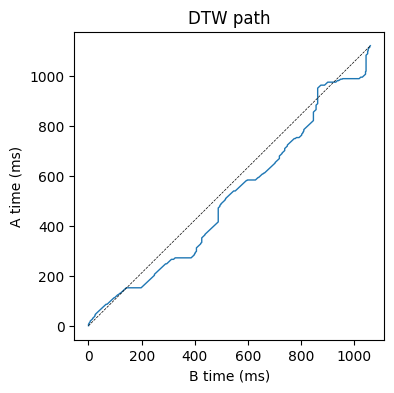

In [ ]:
ia, ib = align(a, b) #algin a and b sounds
plt.figure(figsize=(4, 4))
plt.plot(ib * FRAME_MS, ia * FRAME_MS, lw=1)
plt.plot([0, ib.max() * FRAME_MS], [0, ia.max() * FRAME_MS], "k--", lw=0.5)
plt.xlabel("B time (ms)"); plt.ylabel("A time (ms)"); plt.title("DTW path"); plt.show()

## 6. Generate the morph series
### this first approach can produce scratchy reconstructions relative to how different the original sounds actually are. If noisy/scratchy, move on to Method 2. 

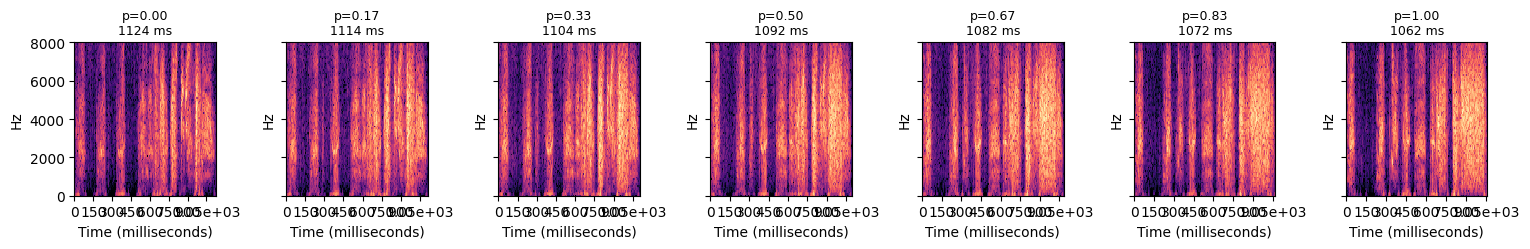

p=0.00


p=0.17


p=0.33


p=0.50


p=0.67


p=0.83


p=1.00


In [ ]:
ps = np.linspace(0, 1, N_STEPS) # estblish morph mixtures based on number of predefined steps, N_STEPS
outs = [morph(a, b, ia, ib, p) for p in ps]

# match RMS across steps so level is not a confound, and add short ramps
rms = lambda s: np.sqrt(np.mean(s ** 2))
target = 0.5 * (rms(a["x"]) + rms(b["x"]))
n = int(0.005 * FS); ramp = 0.5 * (1 - np.cos(np.linspace(0, np.pi, n)))
for k, y in enumerate(outs):
    y *= target / rms(y)
    y[:n] *= ramp; y[-n:] *= ramp[::-1]

fig, axs = plt.subplots(1, N_STEPS, figsize=(2.2 * N_STEPS, 2.6), sharey=True)
for axi, p, y in zip(np.atleast_1d(axs), ps, outs):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=64)), ref=np.max)
    librosa.display.specshow(S, sr=FS, hop_length=64, x_axis="ms", ax=axi, y_axis="hz", cmap="magma")
    axi.set_title(f"p={p:.2f}\n{len(y)/FS*1000:.0f} ms", fontsize=9); axi.set_ylim(0, FMAX_PLOT)
plt.tight_layout(); plt.show()

for p, y in zip(ps, outs):
    print(f"p={p:.2f}"); display(Audio(y, rate=FS))

## 7. Save

In [ ]:
import os
OUT = "morphs"; os.makedirs(OUT, exist_ok=True)
for k, (p, y) in enumerate(zip(ps, outs)):
    sf.write(f"{OUT}/morph_{k}_{int(round(p*100)):03d}.wav", y, FS)
print("saved", len(outs), "files to", OUT)

## 8. Method 2: spectrogram warping (no f0, no source model)

Aligns the two spectrograms with DTW, interpolates the magnitudes, and inverts with Griffin-Lim. It works on any sound, including noisy or multi-component ones, so it is a good check on whether WORLD is the problem.

**Known limitation:** if A and B have harmonics at *different frequencies*, the intermediates cross-fade (both sets of harmonics appear at partial strength) instead of gliding smoothly. Best for pairs with similar pitch structure but different envelope, timing or noise content.

In [22]:
import soundfile as sf

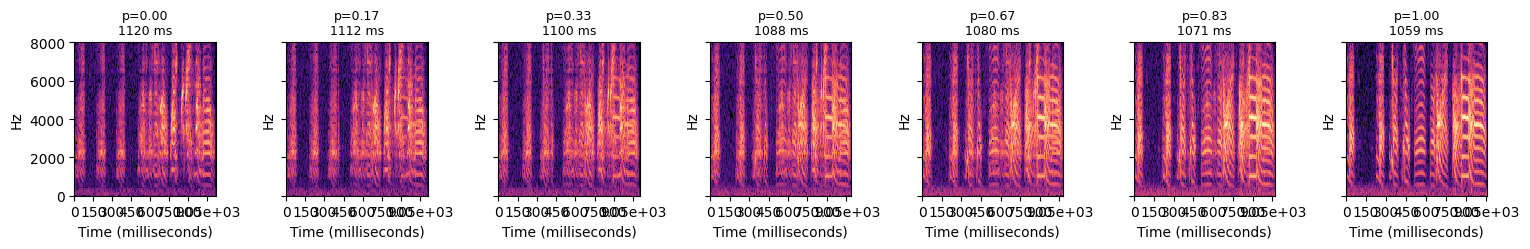

original A


original B


Method 2, p=0.00


Method 2, p=0.17


Method 2, p=0.33


Method 2, p=0.50


Method 2, p=0.67


Method 2, p=0.83


Method 2, p=1.00


In [ ]:
# Configuration for the STFT-based spectrogram morphing pipeline.
N_FFT = 1024       # FFT window size used to calculate the spectrogram.
HOP = 128          # Number of samples between successive STFT frames.
GL_ITERS = 100     # Number of Griffin-Lim iterations for waveform reconstruction.


def spec_of(x):
    """
    Calculate the magnitude spectrogram of an audio waveform.

    The output is transposed so that time frames occupy rows and
    frequency bins occupy columns, matching the format expected by
    the alignment and interpolation functions.

    Parameters
    ----------
    x : numpy.ndarray
        Input audio waveform.

    Returns
    -------
    numpy.ndarray
        Magnitude spectrogram with shape (n_frames, n_frequency_bins).
    """
    return np.abs(
        librosa.stft(x, n_fft=N_FFT, hop_length=HOP)
    ).T


def spec_align(SA, SB):
    """
    Align two magnitude spectrograms using dynamic time warping.

    Mel-frequency cepstral coefficients (MFCCs) are extracted from
    mel-scaled power spectrograms to provide a compact representation
    of the recordings' spectral characteristics. DTW then identifies
    corresponding frames between the two recordings.

    Parameters
    ----------
    SA, SB : numpy.ndarray
        Magnitude spectrograms for recordings A and B, respectively.
        Each array has shape (n_frames, n_frequency_bins).

    Returns
    -------
    tuple of numpy.ndarray
        Floating-point frame indices (ia2, ib2) describing the
        alignment path through recordings A and B.
    """

    def feat(S):
        """
        Convert a magnitude spectrogram into MFCC features.

        Squaring the magnitude produces a power spectrogram, which is
        converted to a mel-frequency representation before computing
        MFCCs. These features are used for alignment rather than for
        reconstructing the audio.
        """
        mel = librosa.feature.melspectrogram(
            S=S.T ** 2,
            sr=FS,
            n_mels=64
        )

        # Convert mel power to decibels before calculating MFCCs.
        return librosa.feature.mfcc(
            S=librosa.power_to_db(mel),
            n_mfcc=20
        )

    # Find the minimum-cost DTW path between the two feature sequences.
    # Euclidean distance measures the difference between MFCC frames.
    _, wp = librosa.sequence.dtw(
        X=feat(SA),
        Y=feat(SB),
        metric="euclidean"
    )

    # Reverse the path so that indices progress forward in time.
    wp = wp[::-1]

    # Return the aligned frame indices for each recording separately.
    # Floating-point indices allow subsequent interpolation between frames.
    return wp[:, 0].astype(float), wp[:, 1].astype(float)


def spec_morph(SA, SB, ia2, ib2, p):
    """
    Create an intermediate waveform by interpolating aligned spectrograms.

    The magnitude spectrograms are aligned using DTW and blended
    according to the morphing coefficient. Griffin-Lim estimates a
    compatible phase representation to reconstruct the time-domain
    waveform from the resulting magnitude spectrogram.

    Parameters
    ----------
    SA, SB : numpy.ndarray
        Magnitude spectrograms for recordings A and B.
    ia2, ib2 : array-like
        Corresponding frame indices returned by `spec_align`.
    p : float
        Morphing coefficient between 0 and 1. A value of 0 selects A's
        spectrogram, while a value of 1 selects B's spectrogram.

    Returns
    -------
    numpy.ndarray
        Reconstructed audio waveform.
    """
    # Determine the number of frames in each source spectrogram.
    nA, nB = SA.shape[0], SB.shape[0]

    # Interpolate the output duration between the two source durations.
    T = int(round((1 - p) * nA + p * nB))

    # Map the DTW correspondence path onto a shared temporal coordinate.
    # The small increasing offset avoids duplicate interpolation positions.
    t_out = (
        (1 - p) * ia2
        + p * ib2
        + 1e-6 * np.arange(len(ia2))
    )

    # Construct the output frame grid and map each position back to
    # the corresponding frame coordinates in the two source spectrograms.
    k = np.arange(T)
    pa = np.interp(k, t_out, ia2)
    pb = np.interp(k, t_out, ib2)

    # Interpolate both spectrograms along their respective alignment paths,
    # then blend their magnitudes using the requested morphing coefficient.
    S = (
        (1 - p) * frame_interp(SA, pa)
        + p * frame_interp(SB, pb)
    )

    # Griffin-Lim iteratively estimates phase information from the
    # magnitude spectrogram so that a time-domain waveform can be generated.
    return librosa.griffinlim(
        S.T,
        n_iter=GL_ITERS,
        hop_length=HOP,
        n_fft=N_FFT
    )


# ---------------------------------------------------------------------
# 1. Calculate spectrograms and align the recordings.


# Convert both source waveforms into magnitude spectrograms.
SA, SB = spec_of(a["x"]), spec_of(b["x"])

# Identify corresponding frames using spectral-feature-based DTW.
ia2, ib2 = spec_align(SA, SB)


# ---------------------------------------------------------------------
# 2. Generate the requested morphing sequence.


# Create one output waveform for each morphing coefficient in `ps`.
# The list preserves the same order as the supplied coefficient values.
outs2 = [
    spec_morph(SA, SB, ia2, ib2, p)
    for p in ps
]


# ---------------------------------------------------------------------
# 3. Normalize output levels and reduce boundary discontinuities.


def rms(z):
    """
    Calculate the root-mean-square (RMS) amplitude of a waveform.

    RMS provides a simple measure of signal level for comparing and
    normalizing the loudness of the generated outputs.
    """
    return np.sqrt(np.mean(z ** 2))


# Use the average RMS level of the two source recordings as the target.
target = 0.5 * (rms(a["x"]) + rms(b["x"]))

# Define a short fade-in/fade-out window to reduce abrupt waveform
# discontinuities at the beginning and end of each synthesized output.
nr = int(0.005 * FS)

# A half-cosine ramp provides a gradual transition from zero to full gain.
rp = 0.5 * (1 - np.cos(np.linspace(0, np.pi, nr)))

for y in outs2:
    # Scale each waveform to the target RMS level.
    # This helps make outputs at different morphing stages comparable.
    y *= target / rms(y)

    # Apply a fade-in and fade-out to reduce clicks caused by abrupt
    # transitions at the waveform boundaries.
    y[:nr] *= rp
    y[-nr:] *= rp[::-1]


# ---------------------------------------------------------------------
# 4. Visualize the generated morphing sequence.


# Create one spectrogram panel per morphing coefficient.
fig, axs = plt.subplots(
    1,
    N_STEPS,
    figsize=(2.2 * N_STEPS, 2.6),
    sharey=True
)

# Ensure the axes object can be iterated over when only one panel exists.
for axi, p, y in zip(np.atleast_1d(axs), ps, outs2):

    # Calculate a spectrogram for visualization. These display settings
    # are independent of the higher-resolution spectrogram used for morphing.
    S = librosa.amplitude_to_db(
        np.abs(librosa.stft(y, n_fft=512, hop_length=64)),
        ref=np.max
    )

    # Display the time-frequency representation in milliseconds and Hz.
    librosa.display.specshow(
        S,
        sr=FS,
        hop_length=64,
        x_axis="ms",
        ax=axi,
        y_axis="hz",
        cmap="magma"
    )

    # Include the morphing coefficient and output duration in the title.
    axi.set_title(
        f"p={p:.2f}\n{len(y) / FS * 1000:.0f} ms",
        fontsize=9
    )

    # Restrict the displayed frequency range for easier comparison.
    axi.set_ylim(0, FMAX_PLOT)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------------------
# 5. Listen to the original recordings and generated outputs.


# Play the source recordings first to provide a reference for the morphs.
print("Original A")
display(Audio(a["x"], rate=FS))

print("Original B")
display(Audio(b["x"], rate=FS))

# Play each generated waveform alongside its corresponding coefficient.
for p, y in zip(ps, outs2):
    print(f"Method 2, p={p:.2f}")
    display(Audio(y, rate=FS))


# ---------------------------------------------------------------------
# 6. Export the generated waveforms as WAV files.


# Directory where the synthesized recordings will be saved.
out_path = r'Z:**\L**ine_Attracto&#x72;**\m**orphs'

for i, (p, y) in enumerate(zip(ps, outs2)):
    # Use the morphing coefficient in the filename to identify each output.
    filename = f"morph_p{p:.2f}.wav"

    # Combine the destination directory and filename into a complete path.
    filepath = os.path.join(out_path, filename)

    # Write the waveform using the project's sampling rate.
    sf.write(filepath, y, FS)

In [ ]:
# save morphs (you can also directly download from above players)

# change path for desired save path

OUT2 = "morphs_spec"; os.makedirs(OUT2, exist_ok=True)
for k, (p, y) in enumerate(zip(ps, outs2)):
    sf.write(f"{OUT2}/morph_{k}_{int(round(p*100)):03d}.wav", y, FS)
print("saved", len(outs2), "files to", OUT2)

# Example code for checking morph viability. 
### specifically, look at plot labeled "Strongest peak". The pointplot should follow the identity line to ensure morph viability

In [76]:
WIN_MS  = (40, 65)      # time window inside each stimulus, in ms
BAND_HZ = (2000, 3600)   # band containing ONE ridge for A and ONE for B

from scipy.signal import windows

def _mean_spec(y, t0, t1, nfft=8192):
    seg = y[int(t0 / 1000 * FS): int(t1 / 1000 * FS)]
    seg = seg * windows.hann(len(seg))
    return np.fft.rfftfreq(nfft, 1 / FS), np.abs(np.fft.rfft(seg, n=nfft)) ** 2

def zoom_plot(outs, ps, label):
    HOPZ, NF = 32, 1024
    Ss = [librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=NF, hop_length=HOPZ))) for y in outs]
    ref = max(S.max() for S in Ss)
    freqs = librosa.fft_frequencies(sr=FS, n_fft=NF)
    fm = (freqs >= BAND_HZ[0] * 0.8) & (freqs <= BAND_HZ[1] * 1.2)
    fig, axs = plt.subplots(1, len(outs), figsize=(2.3 * len(outs), 2.8), sharey=True)
    for ax, S, p in zip(np.atleast_1d(axs), Ss, ps):
        t = np.arange(S.shape[1]) * HOPZ / FS * 1000
        tm = (t >= WIN_MS[0] - 10) & (t <= WIN_MS[1] + 10)
        ax.pcolormesh(t[tm], freqs[fm], S[fm][:, tm], shading="auto", cmap="magma", vmin=ref - 60, vmax=ref)
        ax.axvline(WIN_MS[0], c="c", lw=0.7); ax.axvline(WIN_MS[1], c="c", lw=0.7)
        ax.set_title(f"p={p:.2f}", fontsize=9); ax.set_xlabel("ms")
    np.atleast_1d(axs)[0].set_ylabel("Hz")
    fig.suptitle(f"{label}: zoom (cyan lines = analysis window)", y=1.02, fontsize=10)
    plt.tight_layout(); plt.show()

def ridge_check(outs, ps, label):
    specs = []
    for y in outs:
        f, sp = _mean_spec(y, *WIN_MS); specs.append(sp)
    band = (f >= BAND_HZ[0]) & (f <= BAND_HZ[1])
    fb_, fr_ = f[band], [sp[band] for sp in specs]
    fa, fbb = fb_[np.argmax(fr_[0])], fb_[np.argmax(fr_[-1])]
    D = abs(fbb - fa)
    print(f"[{label}] A ridge = {fa:.0f} Hz, B ridge = {fbb:.0f} Hz, separation = {D:.0f} Hz")
    if D < 100:
        print("  Ridges are <100 Hz apart: too close to tell glide from cross-fade here."
              " Pick another band/window, or confirm both peaks are the same harmonic.")
        return
    w = 0.1 * D; lo, hi = sorted((fa, fbb))
    rA = np.abs(fb_ - fa) <= w; rB = np.abs(fb_ - fbb) <= w; rM = (fb_ > lo + w) & (fb_ < hi - w)
    E = np.array([[r[rA].sum(), r[rM].sum(), r[rB].sum()] for r in fr_])
    E = E / E.sum(1, keepdims=True)
    peak = np.array([fb_[np.argmax(r)] for r in fr_])
    db = [10 * np.log10(r + 1e-12) for r in fr_]
    # two separate peaks (cross-fade): both ridges within 12 dB of the band max AND a >6 dB dip between them
    bimodal = []
    for d in db:
        pa_, pb_ = d[rA].max(), d[rB].max()
        dip = min(pa_, pb_) - d[rM].min() if rM.any() else 0
        bimodal.append(min(pa_, pb_) > d.max() - 12 and dip > 6)

    print("   p     A-band  between  B-band   peak(Hz)  two peaks?")
    for p, e, pk, bm in zip(ps, E, peak, bimodal):
        print(f"  {p:4.2f}   {e[0]:5.2f}   {e[1]:5.2f}   {e[2]:5.2f}   {pk:7.0f}   {'yes' if bm else 'no'}")
    m = int(np.argmin(np.abs(np.array(ps) - 0.5)))
    between_peak = (lo + w) < peak[m] < (hi - w)
    if bimodal[m]:
        verdict = "CROSS-FADE-like: at the mid step both ridges are present as separate peaks"
    elif between_peak:
        verdict = "GLIDE-like: at the mid step there is a single peak located between the two ridges"
    else:
        verdict = "AMBIGUOUS: single peak, but it sits on one of the endpoint ridges (one sound dominates, or the band is off)"
    print(f"  --> {verdict}")

    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
    cm = plt.cm.viridis(np.linspace(0, 1, len(ps)))
    for p, sp, col in zip(ps, specs, cm):
        ax[0].plot(fb_, 10 * np.log10(sp[band] + 1e-12), color=col, lw=1, label=f"p={p:.2f}")
    ax[0].set_xlabel("Hz"); ax[0].set_ylabel("dB"); ax[0].set_title("mean spectrum in window"); ax[0].legend(fontsize=6)
    for j, (nm, col) in enumerate((("A band", "tab:blue"), ("between", "tab:gray"), ("B band", "tab:red"))):
        ax[1].plot(ps, E[:, j], "o-", color=col, label=nm)
    ax[1].set_xlabel("morph p"); ax[1].set_ylabel("fraction of energy"); ax[1].set_title("where the energy is"); ax[1].legend(fontsize=7)
    ax[2].plot(ps, peak, "o-"); ax[2].plot([0, 1], [fa, fbb], "k--", lw=0.8, label="ideal glide")
    ax[2].set_xlabel("morph p"); ax[2].set_ylabel("peak Hz"); ax[2].set_title("strongest peak"); ax[2].legend(fontsize=7)
    fig.suptitle(label, fontsize=10); plt.tight_layout(); plt.show()

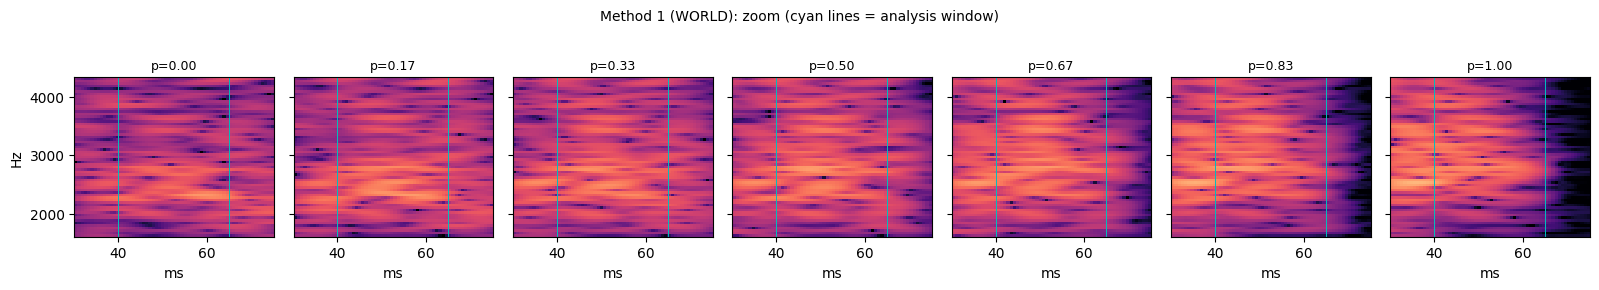

[Method 1 (WORLD)] A ridge = 2336 Hz, B ridge = 2783 Hz, separation = 447 Hz
   p     A-band  between  B-band   peak(Hz)  two peaks?
  0.00    0.25    0.59    0.16      2336   yes
  0.17    0.30    0.51    0.19      2347   yes
  0.33    0.19    0.62    0.20      2492   yes
  0.50    0.13    0.58    0.29      2794   yes
  0.67    0.17    0.42    0.41      2789   yes
  0.83    0.15    0.42    0.42      2783   yes
  1.00    0.09    0.43    0.48      2783   no
  --> CROSS-FADE-like: at the mid step both ridges are present as separate peaks


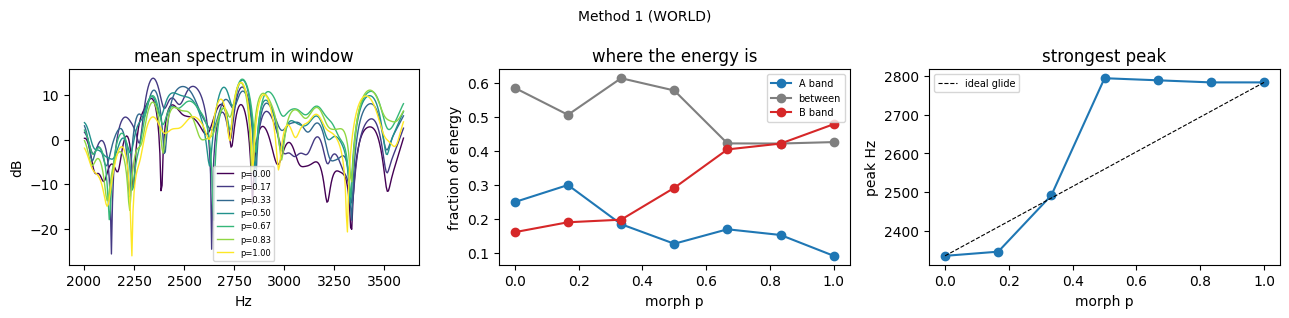

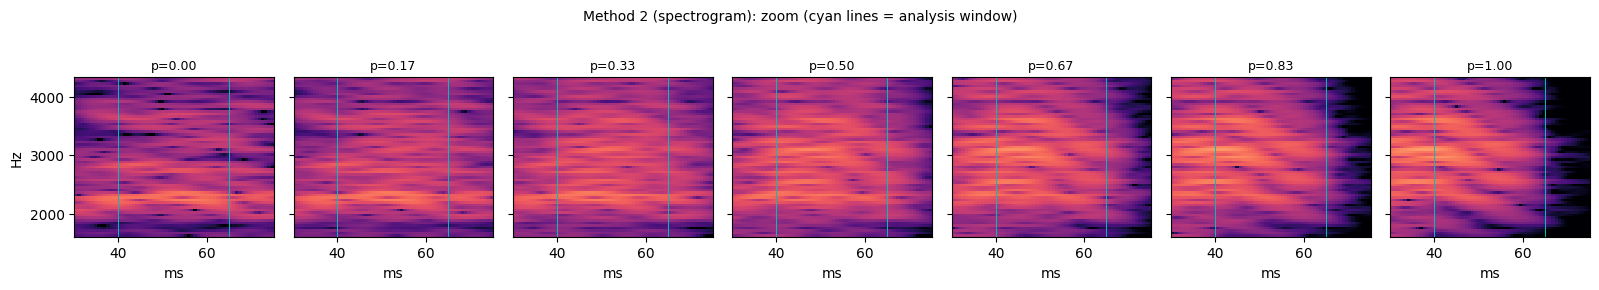

[Method 2 (spectrogram)] A ridge = 2342 Hz, B ridge = 3208 Hz, separation = 867 Hz
   p     A-band  between  B-band   peak(Hz)  two peaks?
  0.00    0.61    0.34    0.05      2342   yes
  0.17    0.47    0.44    0.08      2347   yes
  0.33    0.32    0.55    0.13      2336   yes
  0.50    0.23    0.64    0.14      2320   yes
  0.67    0.20    0.69    0.11      2966   yes
  0.83    0.19    0.62    0.19      2896   yes
  1.00    0.07    0.61    0.31      3208   yes
  --> CROSS-FADE-like: at the mid step both ridges are present as separate peaks


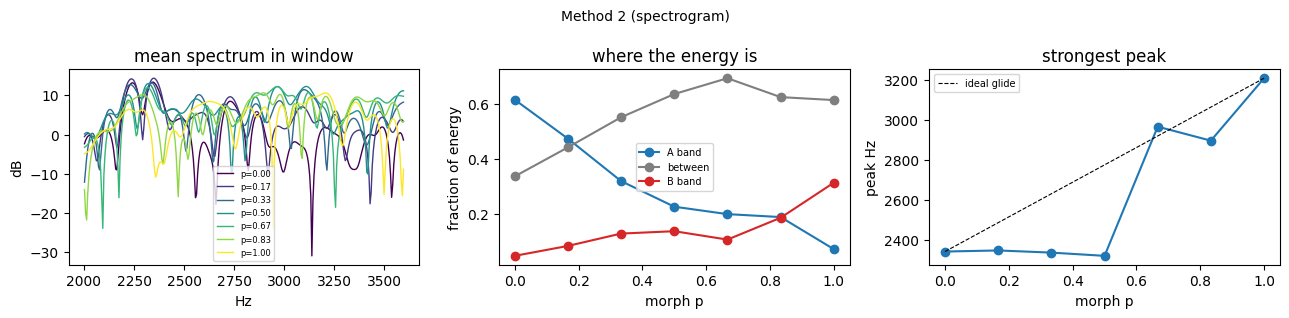

In [77]:
zoom_plot(outs, ps, "Method 1 (WORLD)")
ridge_check(outs, ps, "Method 1 (WORLD)")
if "outs2" in globals():
    zoom_plot(outs2, ps, "Method 2 (spectrogram)")
    ridge_check(outs2, ps, "Method 2 (spectrogram)")